In [1]:
import torch
import matplotlib.pyplot as plt

In [2]:
lrs = [1e-2, 3e-2, 1e-1]
beta_Hs = torch.logspace(0, 3, 8)
beta_Gs = torch.logspace(0, 3, 8)

num_steps = 10000
log_interval = 10
steps = torch.arange(1, (num_steps // log_interval) + 1) * log_interval

test_losses = torch.zeros(len(lrs), len(beta_Hs), len(beta_Gs), num_steps // log_interval)
s_beta_H = torch.zeros(len(lrs), len(beta_Hs), len(beta_Gs), num_steps // log_interval)
s_beta_G = torch.zeros(len(lrs), len(beta_Hs), len(beta_Gs), num_steps // log_interval)
V_diff = torch.zeros(len(lrs), len(beta_Hs), len(beta_Gs), num_steps // log_interval)

for task_id in range(192):
    data = torch.load(f"../outputs/exp-0-{task_id}.pt", weights_only=True)
    lr_id, beta_H_id, beta_G_id = task_id % 3, (task_id // 3) % 8, (task_id // 3) // 8
    test_losses[lr_id, beta_H_id, beta_G_id] = data["test_losses"]
    s_beta_H[lr_id, beta_H_id, beta_G_id] = data["s_beta_H"]
    s_beta_G[lr_id, beta_H_id, beta_G_id] = data["s_beta_G"]
    V_diff[lr_id, beta_H_id, beta_G_id] = data["V_diff"]

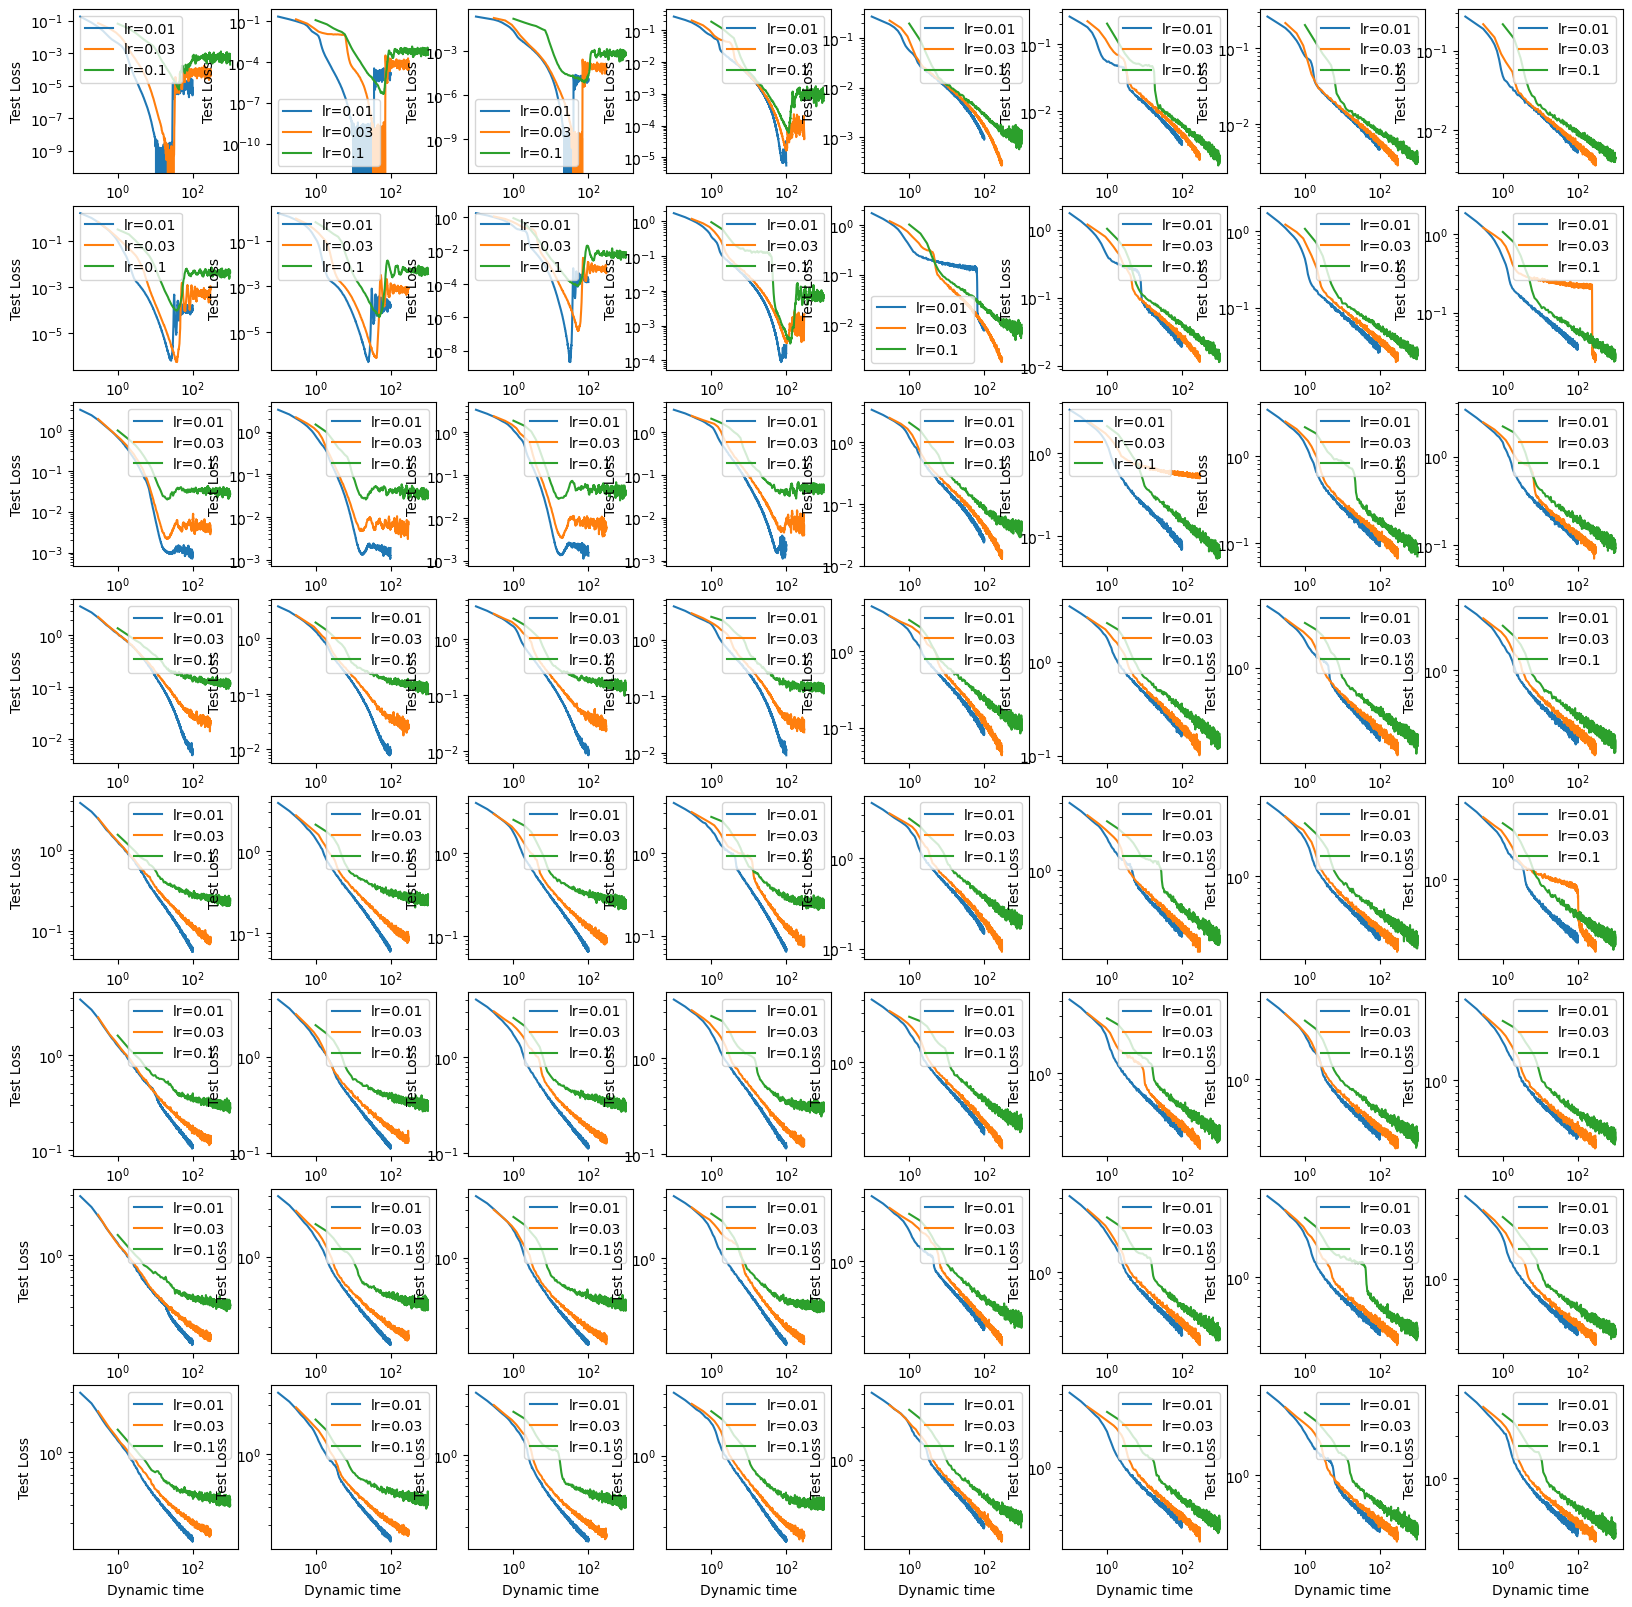

In [3]:
# 8 x 8 subplots
fig, axes = plt.subplots(8, 8, figsize=(20, 20))
for beta_H_id in range(8):
    for beta_G_id in range(8):
        ax = axes[beta_H_id, beta_G_id]
        for lr_id in range(3):
            ax.plot(steps.numpy() * lrs[lr_id], test_losses[lr_id, beta_H_id, beta_G_id], label=f"lr={lrs[lr_id]}")
        ax.set_xlabel("Dynamic time")
        ax.set_ylabel("Test Loss")
        ax.legend()
        ax.set_xscale("log")
        ax.set_yscale("log")

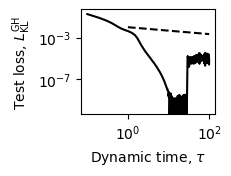

In [4]:
plt.figure(figsize=(2.2, 1.65), constrained_layout=True)
beta_H_id = 0
beta_G_id = 0
lr_id = 0
plt.plot(steps.numpy() * lrs[lr_id], test_losses[lr_id, beta_H_id, beta_G_id], 'k-')
plt.plot([1e+0,1e+2], [.01, .01 / (1e+2) ** (1/3)], 'k--')
#plt.xlim(5e+1, 2e+5)
plt.yscale("log")
plt.xscale("log")
plt.xlabel(r"Dynamic time, $\tau$")
plt.ylabel(r"Test loss, $L_{\rm KL}^{\rm GH}$")
plt.savefig("../../figures/GHleftbottomAdam.pdf")

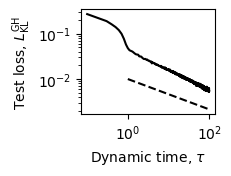

In [5]:
plt.figure(figsize=(2.2, 1.65), constrained_layout=True)
beta_H_id = 0
beta_G_id = -1
lr_id = 0
plt.plot(steps.numpy() * lrs[lr_id], test_losses[lr_id, beta_H_id, beta_G_id], 'k-')
plt.plot([1e+0,1e+2], [.01, .01 / (1e+2) ** (1/3)], 'k--')
#plt.xlim(5e+1, 2e+5)
plt.yscale("log")
plt.xscale("log")
plt.xlabel(r"Dynamic time, $\tau$")
plt.ylabel(r"Test loss, $L_{\rm KL}^{\rm GH}$")
plt.savefig("../../figures/GHrightbottomAdam.pdf")

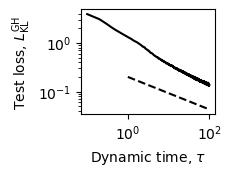

In [6]:
plt.figure(figsize=(2.2, 1.65), constrained_layout=True)
beta_H_id = -1
beta_G_id = 0
lr_id = 0
plt.plot(steps.numpy() * lrs[lr_id], test_losses[lr_id, beta_H_id, beta_G_id], 'k-')
plt.plot([1e+0,1e+2], [.2, .2 / (1e+2) ** (1/3)], 'k--')
#plt.ylim(1e-1, None)
plt.yscale("log")
plt.xscale("log")
plt.xlabel(r"Dynamic time, $\tau$")
plt.ylabel(r"Test loss, $L_{\rm KL}^{\rm GH}$")
plt.savefig("../../figures/GHlefttopAdam.pdf")

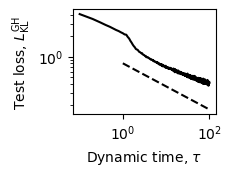

In [7]:
plt.figure(figsize=(2.2, 1.65), constrained_layout=True)
beta_H_id = -1
beta_G_id = -1
lr_id = 0
plt.plot(steps.numpy() * lrs[lr_id], test_losses[lr_id, beta_H_id, beta_G_id], 'k-')
plt.plot([1e+0,1e+2], [.8, .8 / (1e+2) ** (1/3)], 'k--')
#plt.ylim(1e-1, None)
plt.yscale("log")
plt.xscale("log")
plt.xlabel(r"Dynamic time, $\tau$")
plt.ylabel(r"Test loss, $L_{\rm KL}^{\rm GH}$")
plt.savefig("../../figures/GHrighttopAdam.pdf")

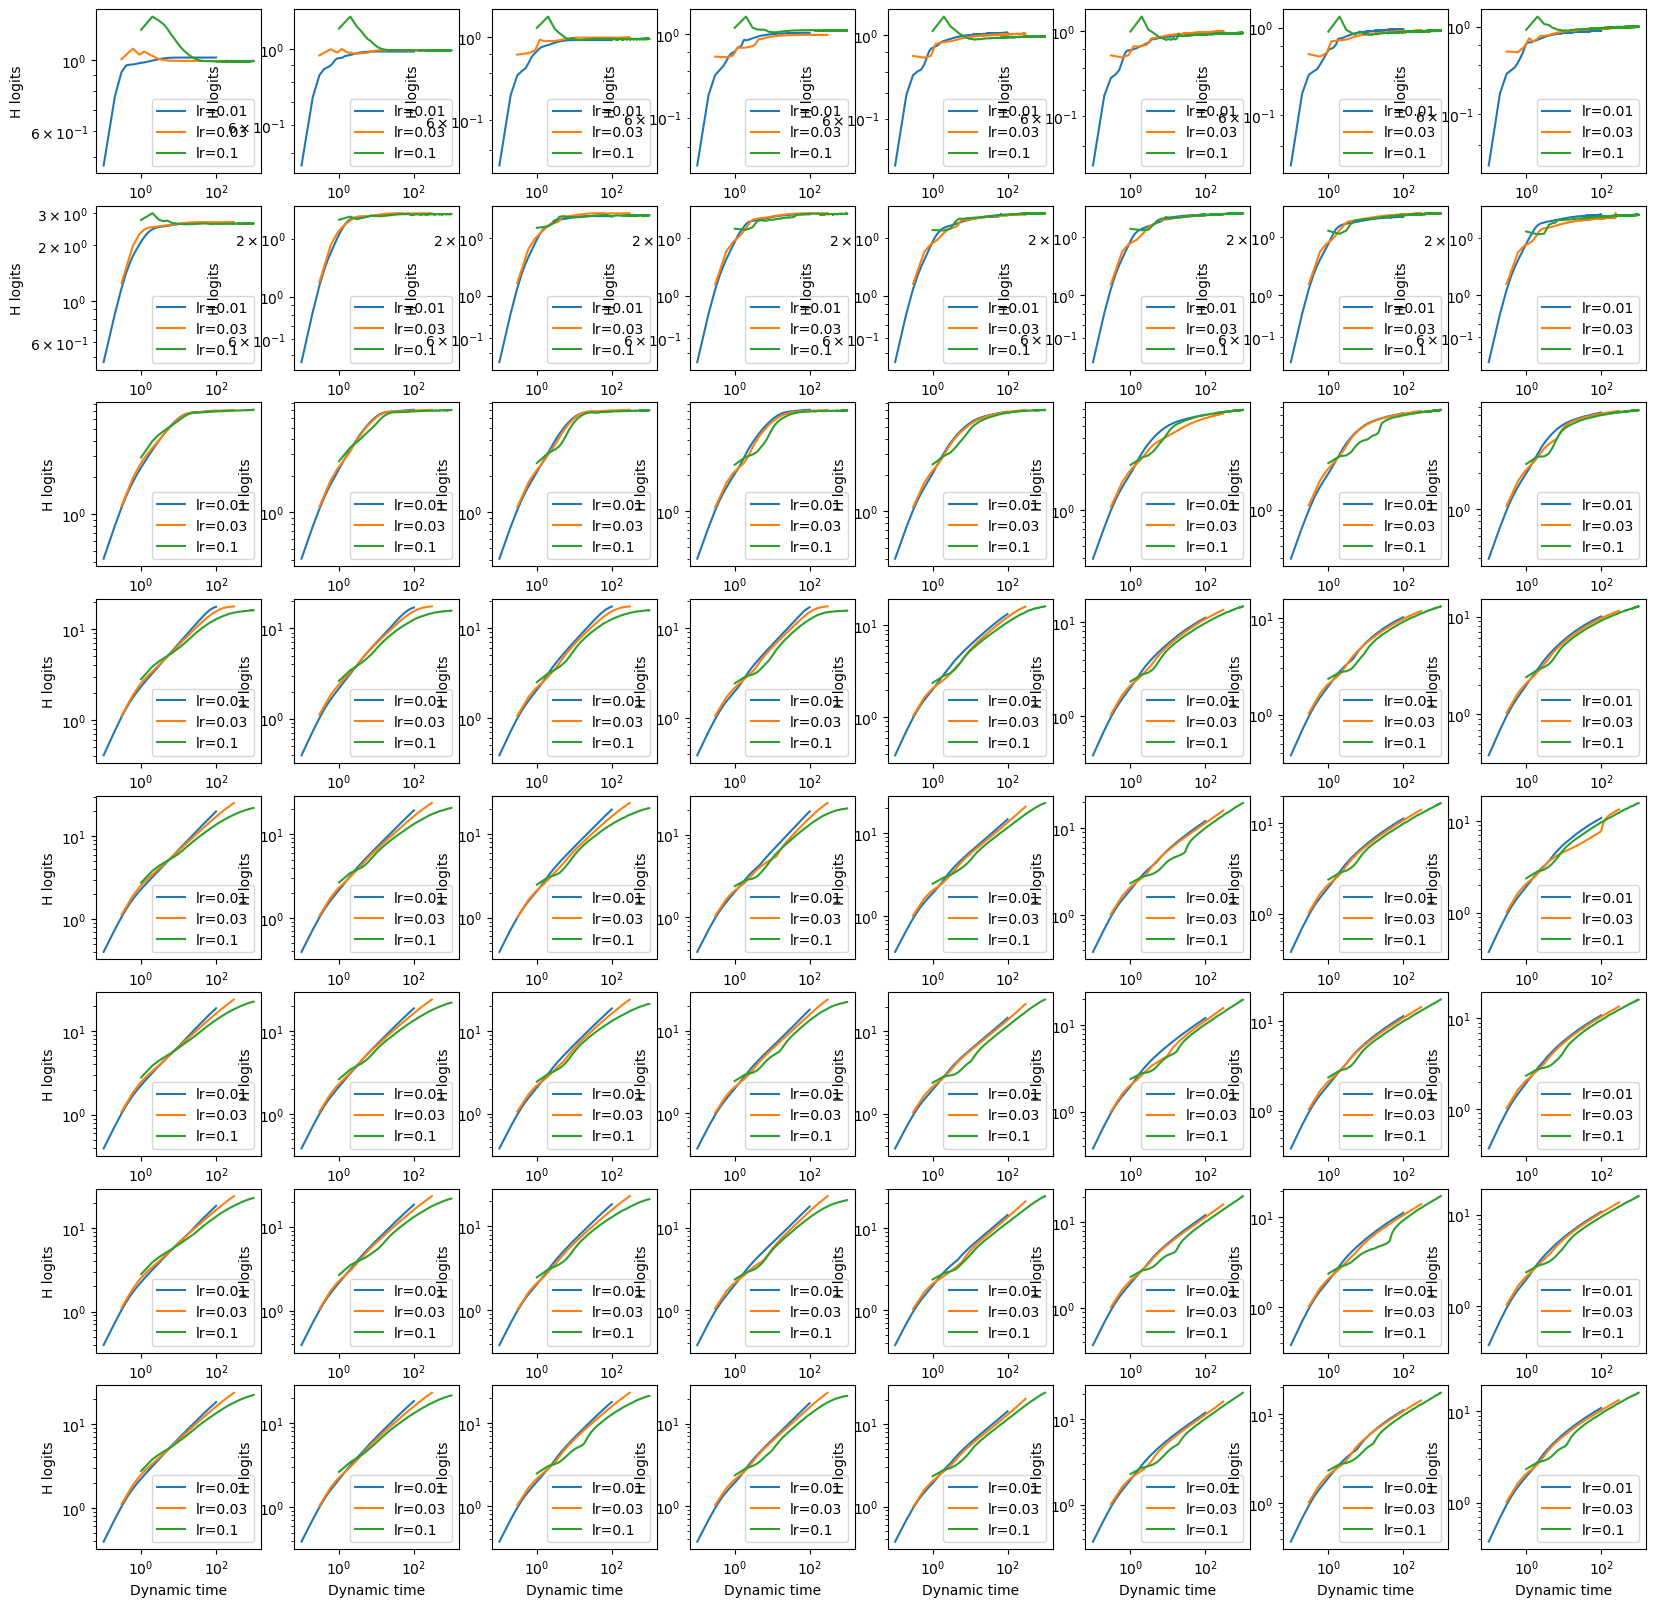

In [5]:
# 8 x 8 subplots
fig, axes = plt.subplots(8, 8, figsize=(20, 20))
for beta_H_id in range(8):
    for beta_G_id in range(8):
        ax = axes[beta_H_id, beta_G_id]
        for lr_id in range(3):
            ax.plot(steps.numpy() * lrs[lr_id], s_beta_H[lr_id, beta_H_id, beta_G_id], label=f"lr={lrs[lr_id]}")
        ax.set_xlabel("Dynamic time")
        ax.set_ylabel("H logits")
        ax.legend()
        ax.set_xscale("log")
        ax.set_yscale("log")

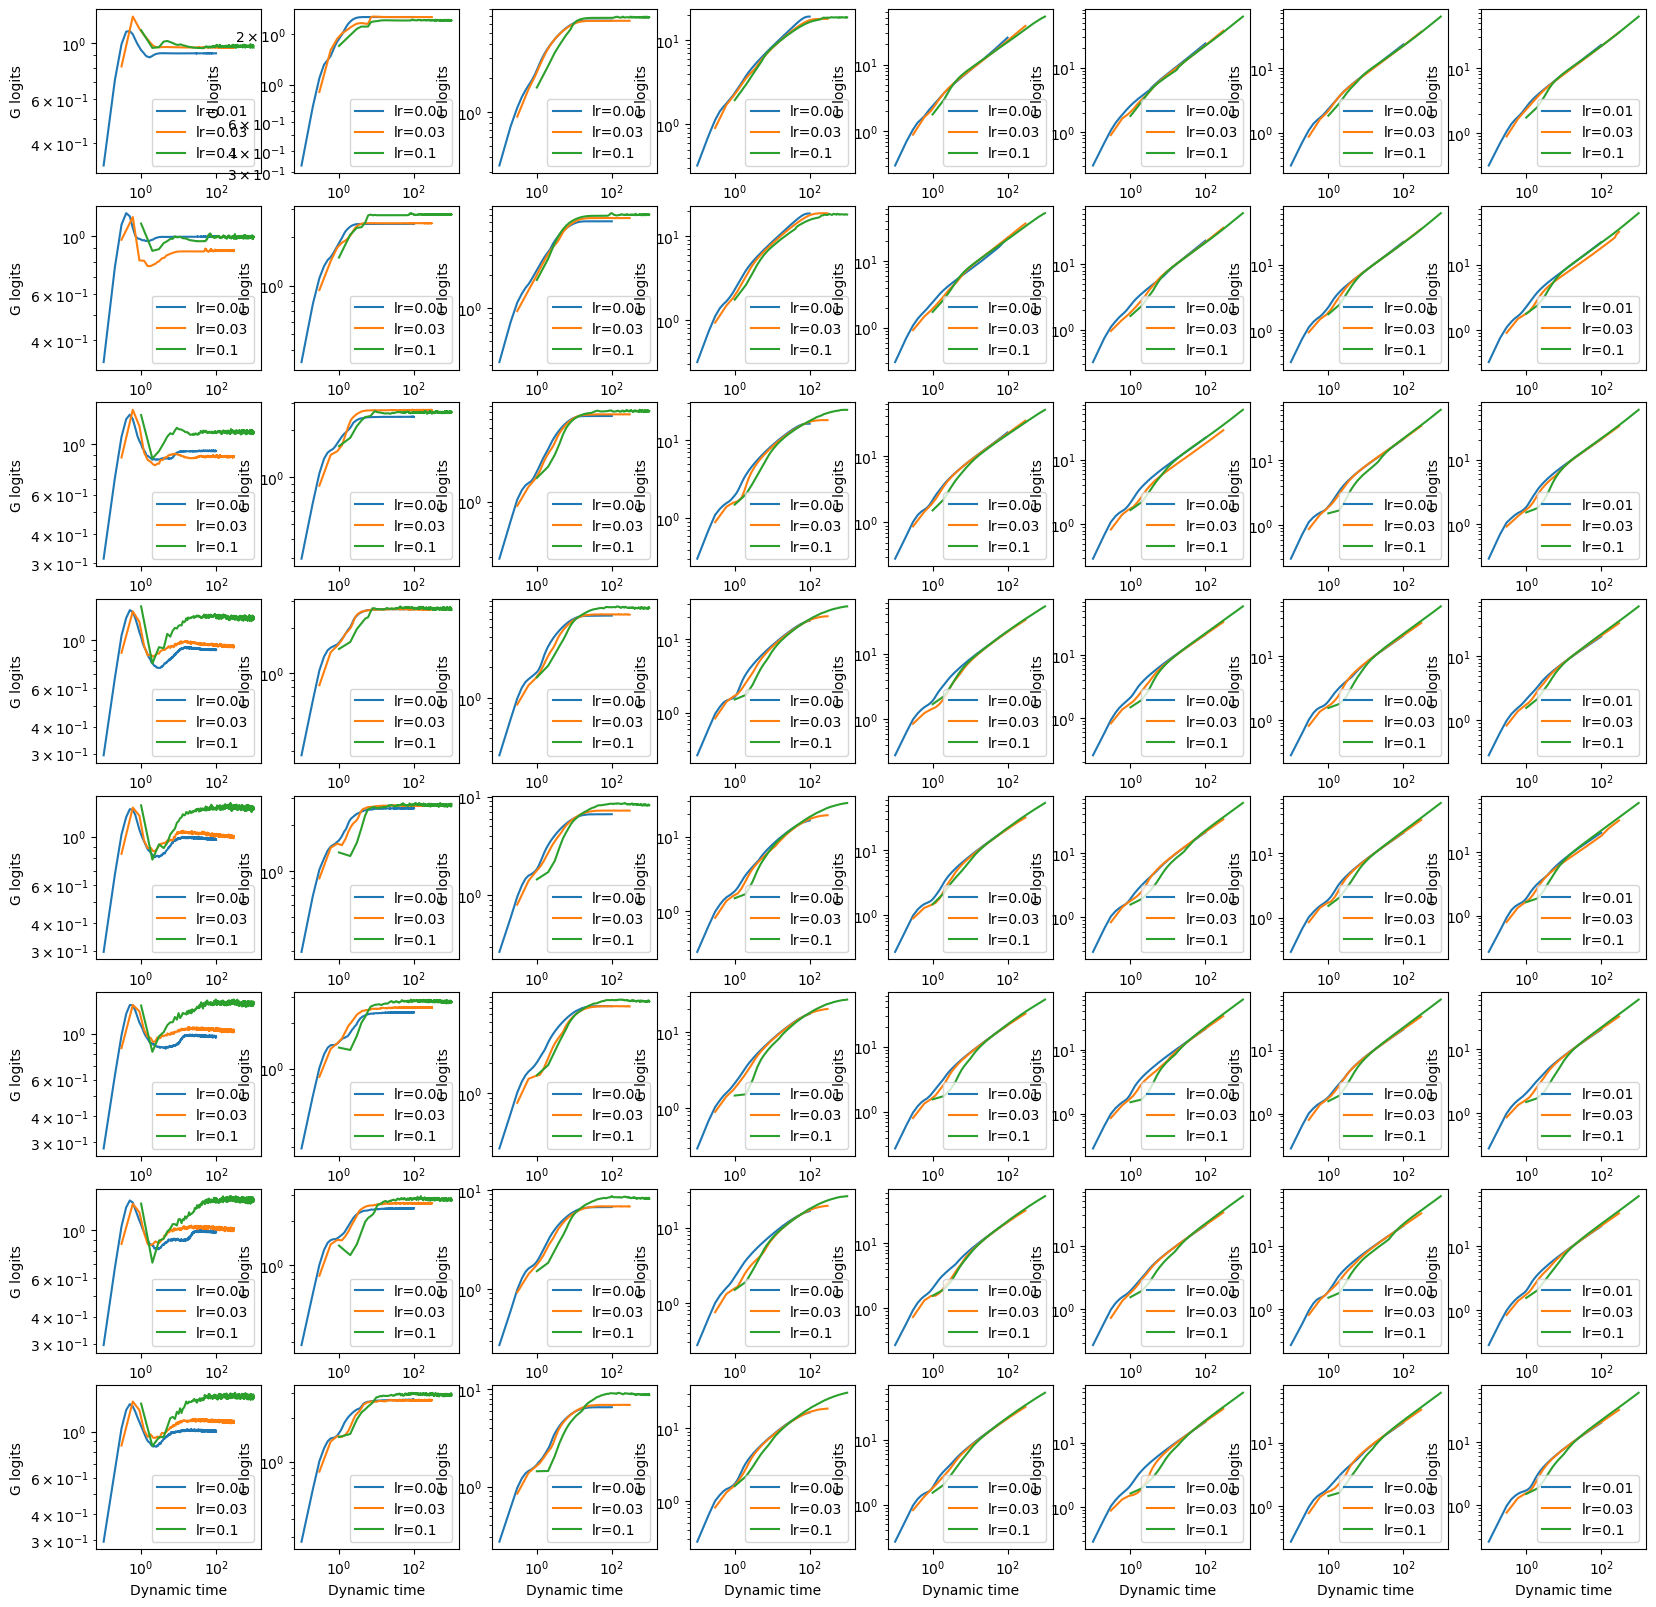

In [6]:
# 8 x 8 subplots
fig, axes = plt.subplots(8, 8, figsize=(20, 20))
for beta_H_id in range(8):
    for beta_G_id in range(8):
        ax = axes[beta_H_id, beta_G_id]
        for lr_id in range(3):
            ax.plot(steps.numpy() * lrs[lr_id], s_beta_G[lr_id, beta_H_id, beta_G_id], label=f"lr={lrs[lr_id]}")
        ax.set_xlabel("Dynamic time")
        ax.set_ylabel("G logits")
        ax.legend()
        ax.set_xscale("log")
        ax.set_yscale("log")

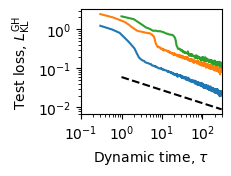

In [8]:
plt.figure(figsize=(2.2, 1.65), constrained_layout=True)
lr_id = 1
beta_G_id = -2
for beta_H_id in [1]:
    plt.plot(steps.numpy() * lrs[lr_id], test_losses[lr_id, beta_H_id, beta_G_id])
lr_id = 1
beta_G_id = -1
for beta_H_id in [2]:
    plt.plot(steps.numpy() * lrs[lr_id], test_losses[lr_id, beta_H_id, beta_G_id])
lr_id = 2
beta_G_id = -2
for beta_H_id in [2]:
    plt.plot(steps.numpy() * lrs[lr_id], test_losses[lr_id, beta_H_id, beta_G_id])
plt.plot([1e+0,3e+2], [.06, .06 / (3e+2) ** (1/3)], 'k--')
plt.xlim(1e-1, 3e+2)
plt.xlabel(r"Dynamic time, $\tau$")
plt.ylabel(r"Test loss, $L_{\rm KL}^{\rm GH}$")
plt.xscale("log")
plt.yscale("log")
plt.savefig("../../figures/lossstepAdam.pdf")

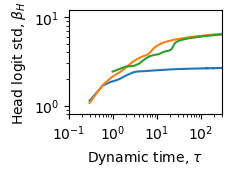

In [22]:
plt.figure(figsize=(2.2, 1.65), constrained_layout=True)
lr_id = 1
beta_G_id = -2
for beta_H_id in [1]:
    plt.plot(steps.numpy() * lrs[lr_id], s_beta_H[lr_id, beta_H_id, beta_G_id])
lr_id = 1
beta_G_id = -1
for beta_H_id in [2]:
    plt.plot(steps.numpy() * lrs[lr_id], s_beta_H[lr_id, beta_H_id, beta_G_id])
lr_id = 2
beta_G_id = -2
for beta_H_id in [2]:
    plt.plot(steps.numpy() * lrs[lr_id], s_beta_H[lr_id, beta_H_id, beta_G_id])
plt.xscale("log")
plt.yscale("log")
plt.xlim(1e-1, 3e+2)
plt.ylim(8e-1, 1.2e+1)
plt.xlabel(r"Dynamic time, $\tau$")
plt.ylabel(r"Head logit std, $\beta_H$")
plt.yticks([1,10], labels=[r"$10^{0}$", r"$10^1$"])
#plt.minorticks_off()
plt.savefig("../../figures/HlogitstepAdam.pdf")

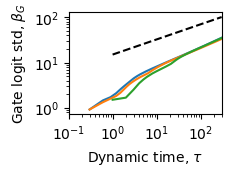

In [10]:
plt.figure(figsize=(2.2, 1.65), constrained_layout=True)
lr_id = 1
beta_G_id = -2
for beta_H_id in [1]:
    plt.plot(steps.numpy() * lrs[lr_id], s_beta_G[lr_id, beta_H_id, beta_G_id])
lr_id = 1
beta_G_id = -1
for beta_H_id in [2]:
    plt.plot(steps.numpy() * lrs[lr_id], s_beta_G[lr_id, beta_H_id, beta_G_id])
lr_id = 2
beta_G_id = -2
for beta_H_id in [2]:
    plt.plot(steps.numpy() * lrs[lr_id], s_beta_G[lr_id, beta_H_id, beta_G_id])
plt.plot([1e+0,3e+2], [15, 15 * (3e+2) ** (1/3)], 'k--')
plt.xscale("log")
plt.yscale("log")
plt.xlim(1e-1, 3e+2)
#plt.ylim(1e-1, None)
plt.xlabel(r"Dynamic time, $\tau$")
plt.ylabel(r"Gate logit std, $\beta_G$")
plt.savefig("../../figures/GlogitstepAdam.pdf")